c:\Users\Paimon\miniconda3\envs\ml_project\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Paimon\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1
Unknown in CLIENTNUM: 0 
Unknown in Attrition_Flag: 0 
Unknown in Customer_Age: 0 
Unknown in Gender: 0 
Unknown in Dependent_count: 0 
Unknown in Education_Level: 1519 
Unknown in Marital_Status: 749 
Unknown in Income_Category: 1112 
Unknown in Card_Category: 0 
Unknown in Months_on_book: 0 
Unknown in Total_Relationship_Count: 0 
Unknown in Months_Inactive_12_mon: 0 
Unknown in Contacts_Count_12_mon: 0 
Unknown in Credit_Limit: 0 
Unknown in Total_Revolving_Bal: 0 
Unknown in Avg_Open_To_Buy: 0 
Unknown in Total_Amt_Chng_Q4_Q1: 0 
Unknown in Total_Trans_Amt: 0 
Unknown in Total_Trans_Ct: 0 
Unknown in Total_Ct_Chng_Q4_Q1: 0 
Unknown in Avg_Utilization_Ratio: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contact

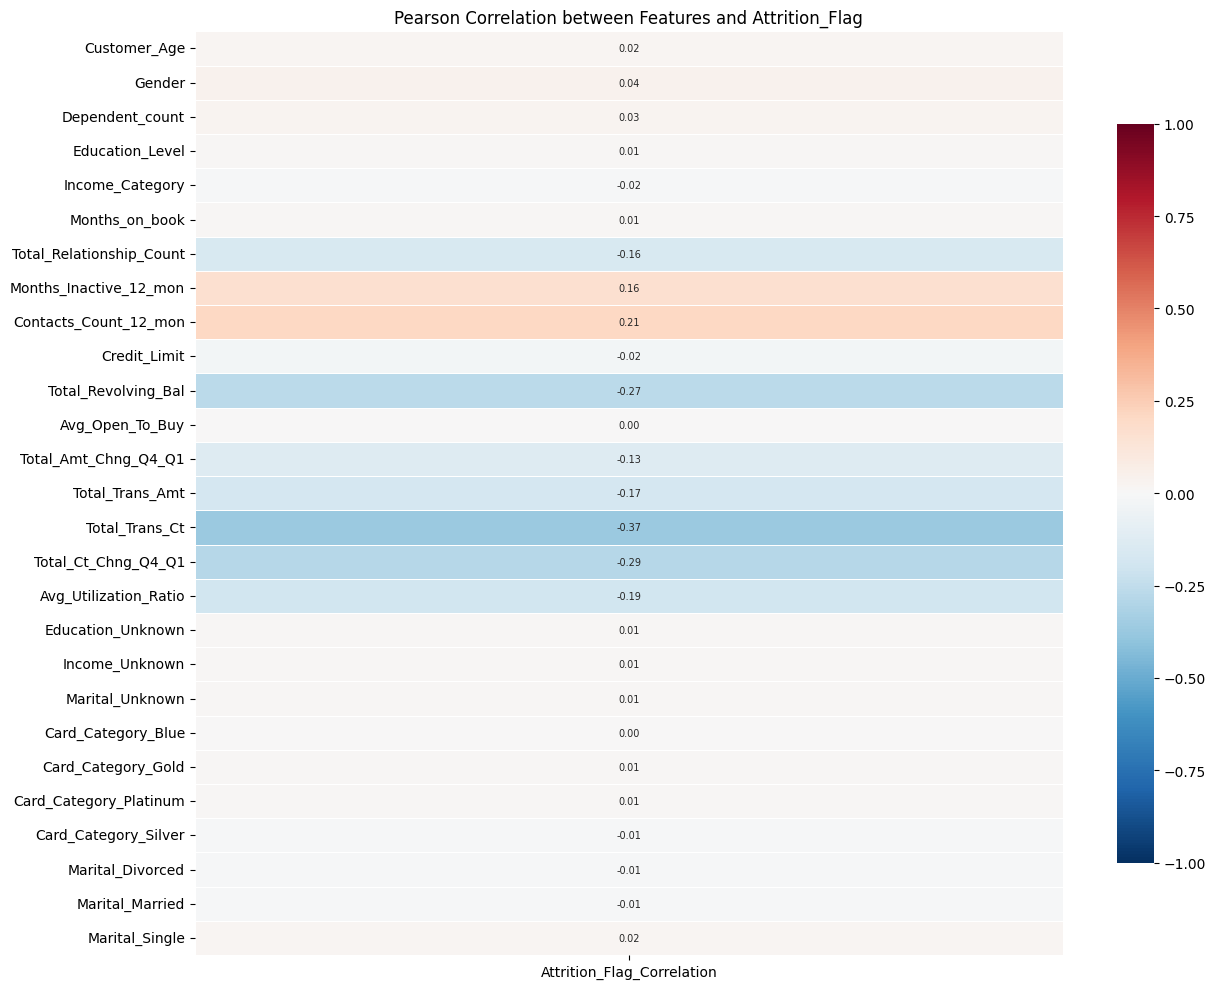

                     feature        score         pvalue  mutual_info  \
0             Total_Trans_Ct  1304.840615  4.672547e-265     0.117308   
1        Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107   
2        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718   
3      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237   
4      Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820   
5            Total_Trans_Amt   251.300721   9.267982e-56     0.158251   
6     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610   
7   Total_Relationship_Count   204.922922   6.377533e-46     0.012831   
8       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095   
9            Dependent_count     7.760686   5.351984e-03     0.002122   
10              Credit_Limit     4.658394   3.093137e-02     0.000305   
11              Customer_Age     2.412416   1.204155e-01     0.000000   
12            Months_on_book     0.534546   4.64723

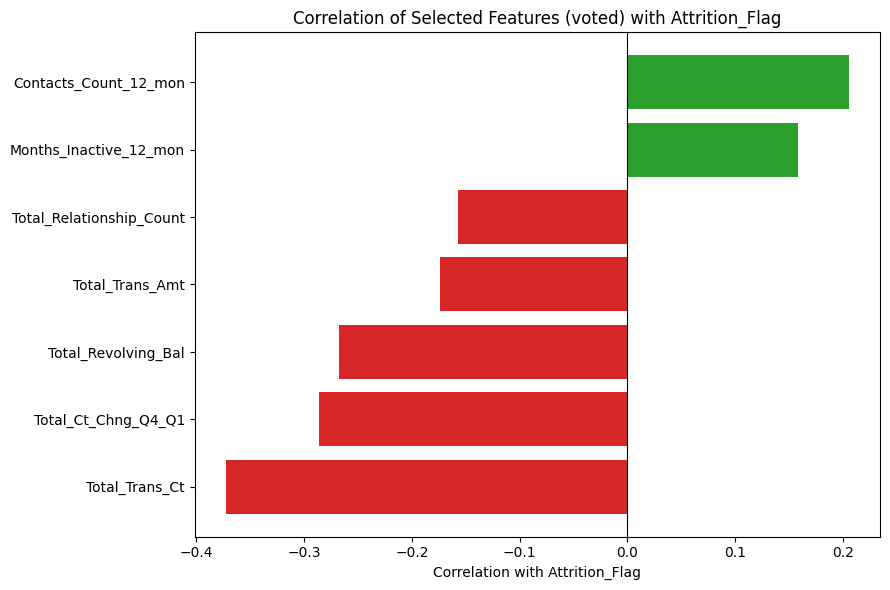

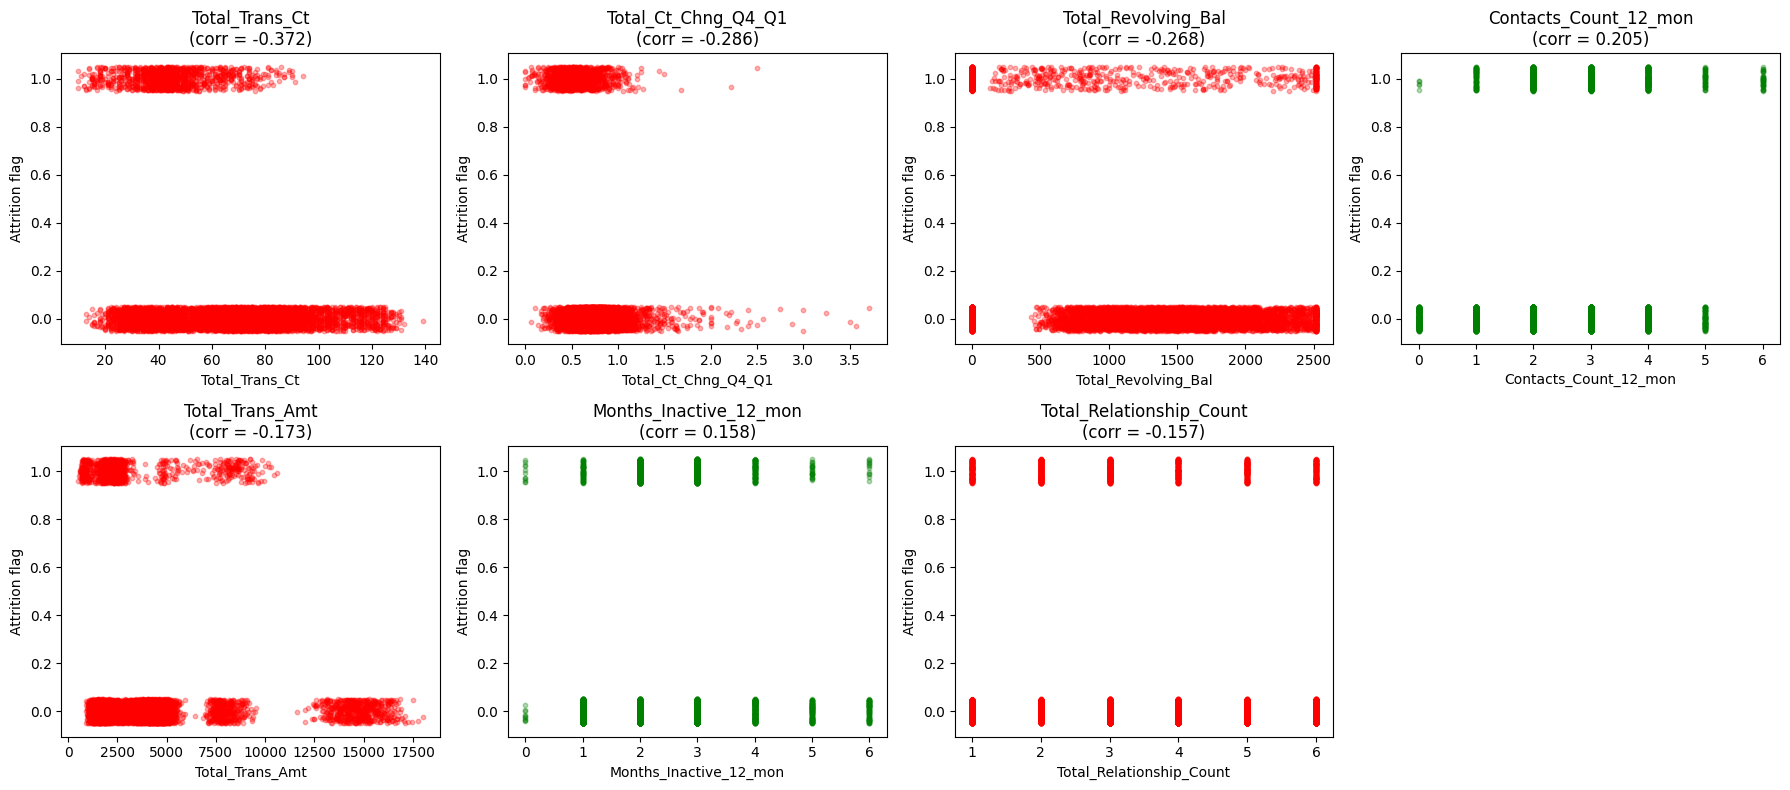

ฟีเจอร์: 25
Train: 8101 | Test: 2026

Income_Category             0.563
Card_Category_Blue          0.516
Card_Category_Silver        0.441
Gender                      0.421
Card_Category_Gold          0.234
Total_Trans_Amt             0.172
Card_Category_Platinum      0.106
Total_Trans_Ct              0.076
Total_Relationship_Count    0.071
Dependent_count             0.068
                 feature       score        pvalue  mutual_info
         Income_Category 3818.741260  0.000000e+00     0.211580
      Card_Category_Blue 2860.832605  0.000000e+00     0.116305
    Card_Category_Silver 1863.773769  0.000000e+00     0.084387
                  Gender 1793.463987  0.000000e+00     0.130455
      Card_Category_Gold  519.128770 1.972602e-111     0.030937
         Total_Trans_Amt  242.378319  7.156694e-54     0.106803
  Card_Category_Platinum   75.218274  5.036403e-18     0.006265
          Total_Trans_Ct   46.951240  7.810232e-12     0.039888
Total_Relationship_Count   42.747424  6.605692

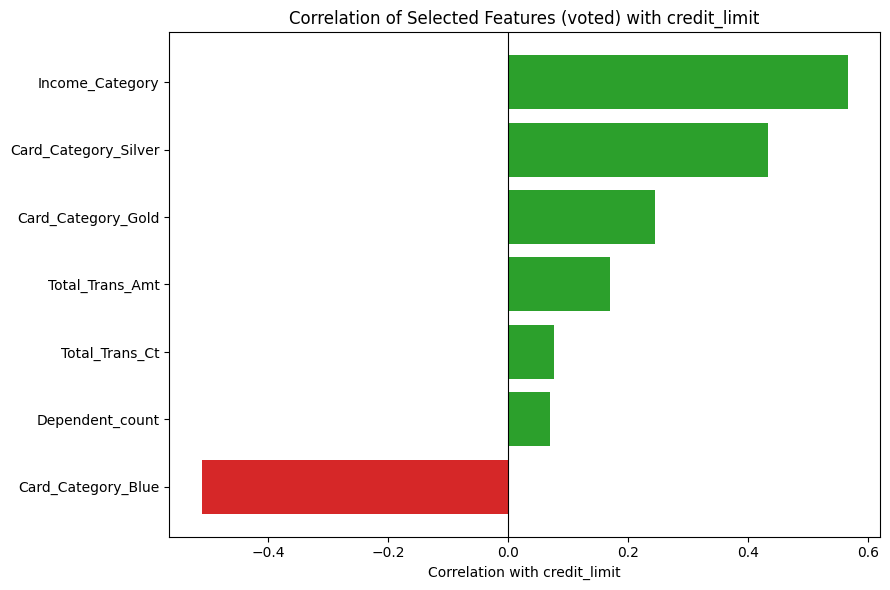

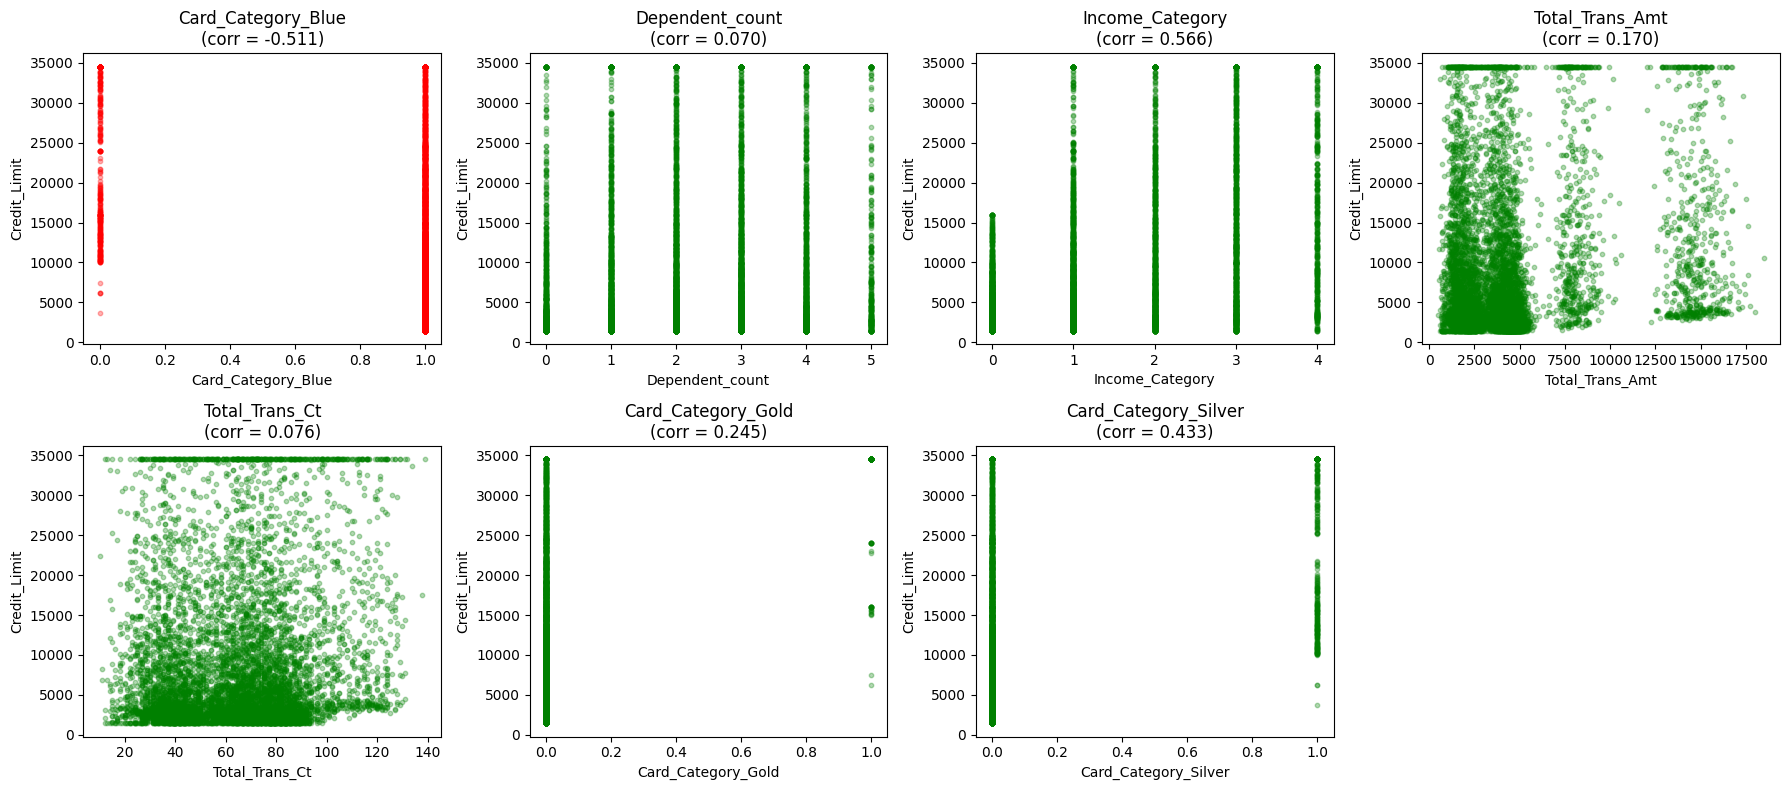

R² each fold: [0.5178384  0.55896333 0.51699789 0.55879163 0.56659464]
Mean R²: 0.5438 (+/- 0.0218)


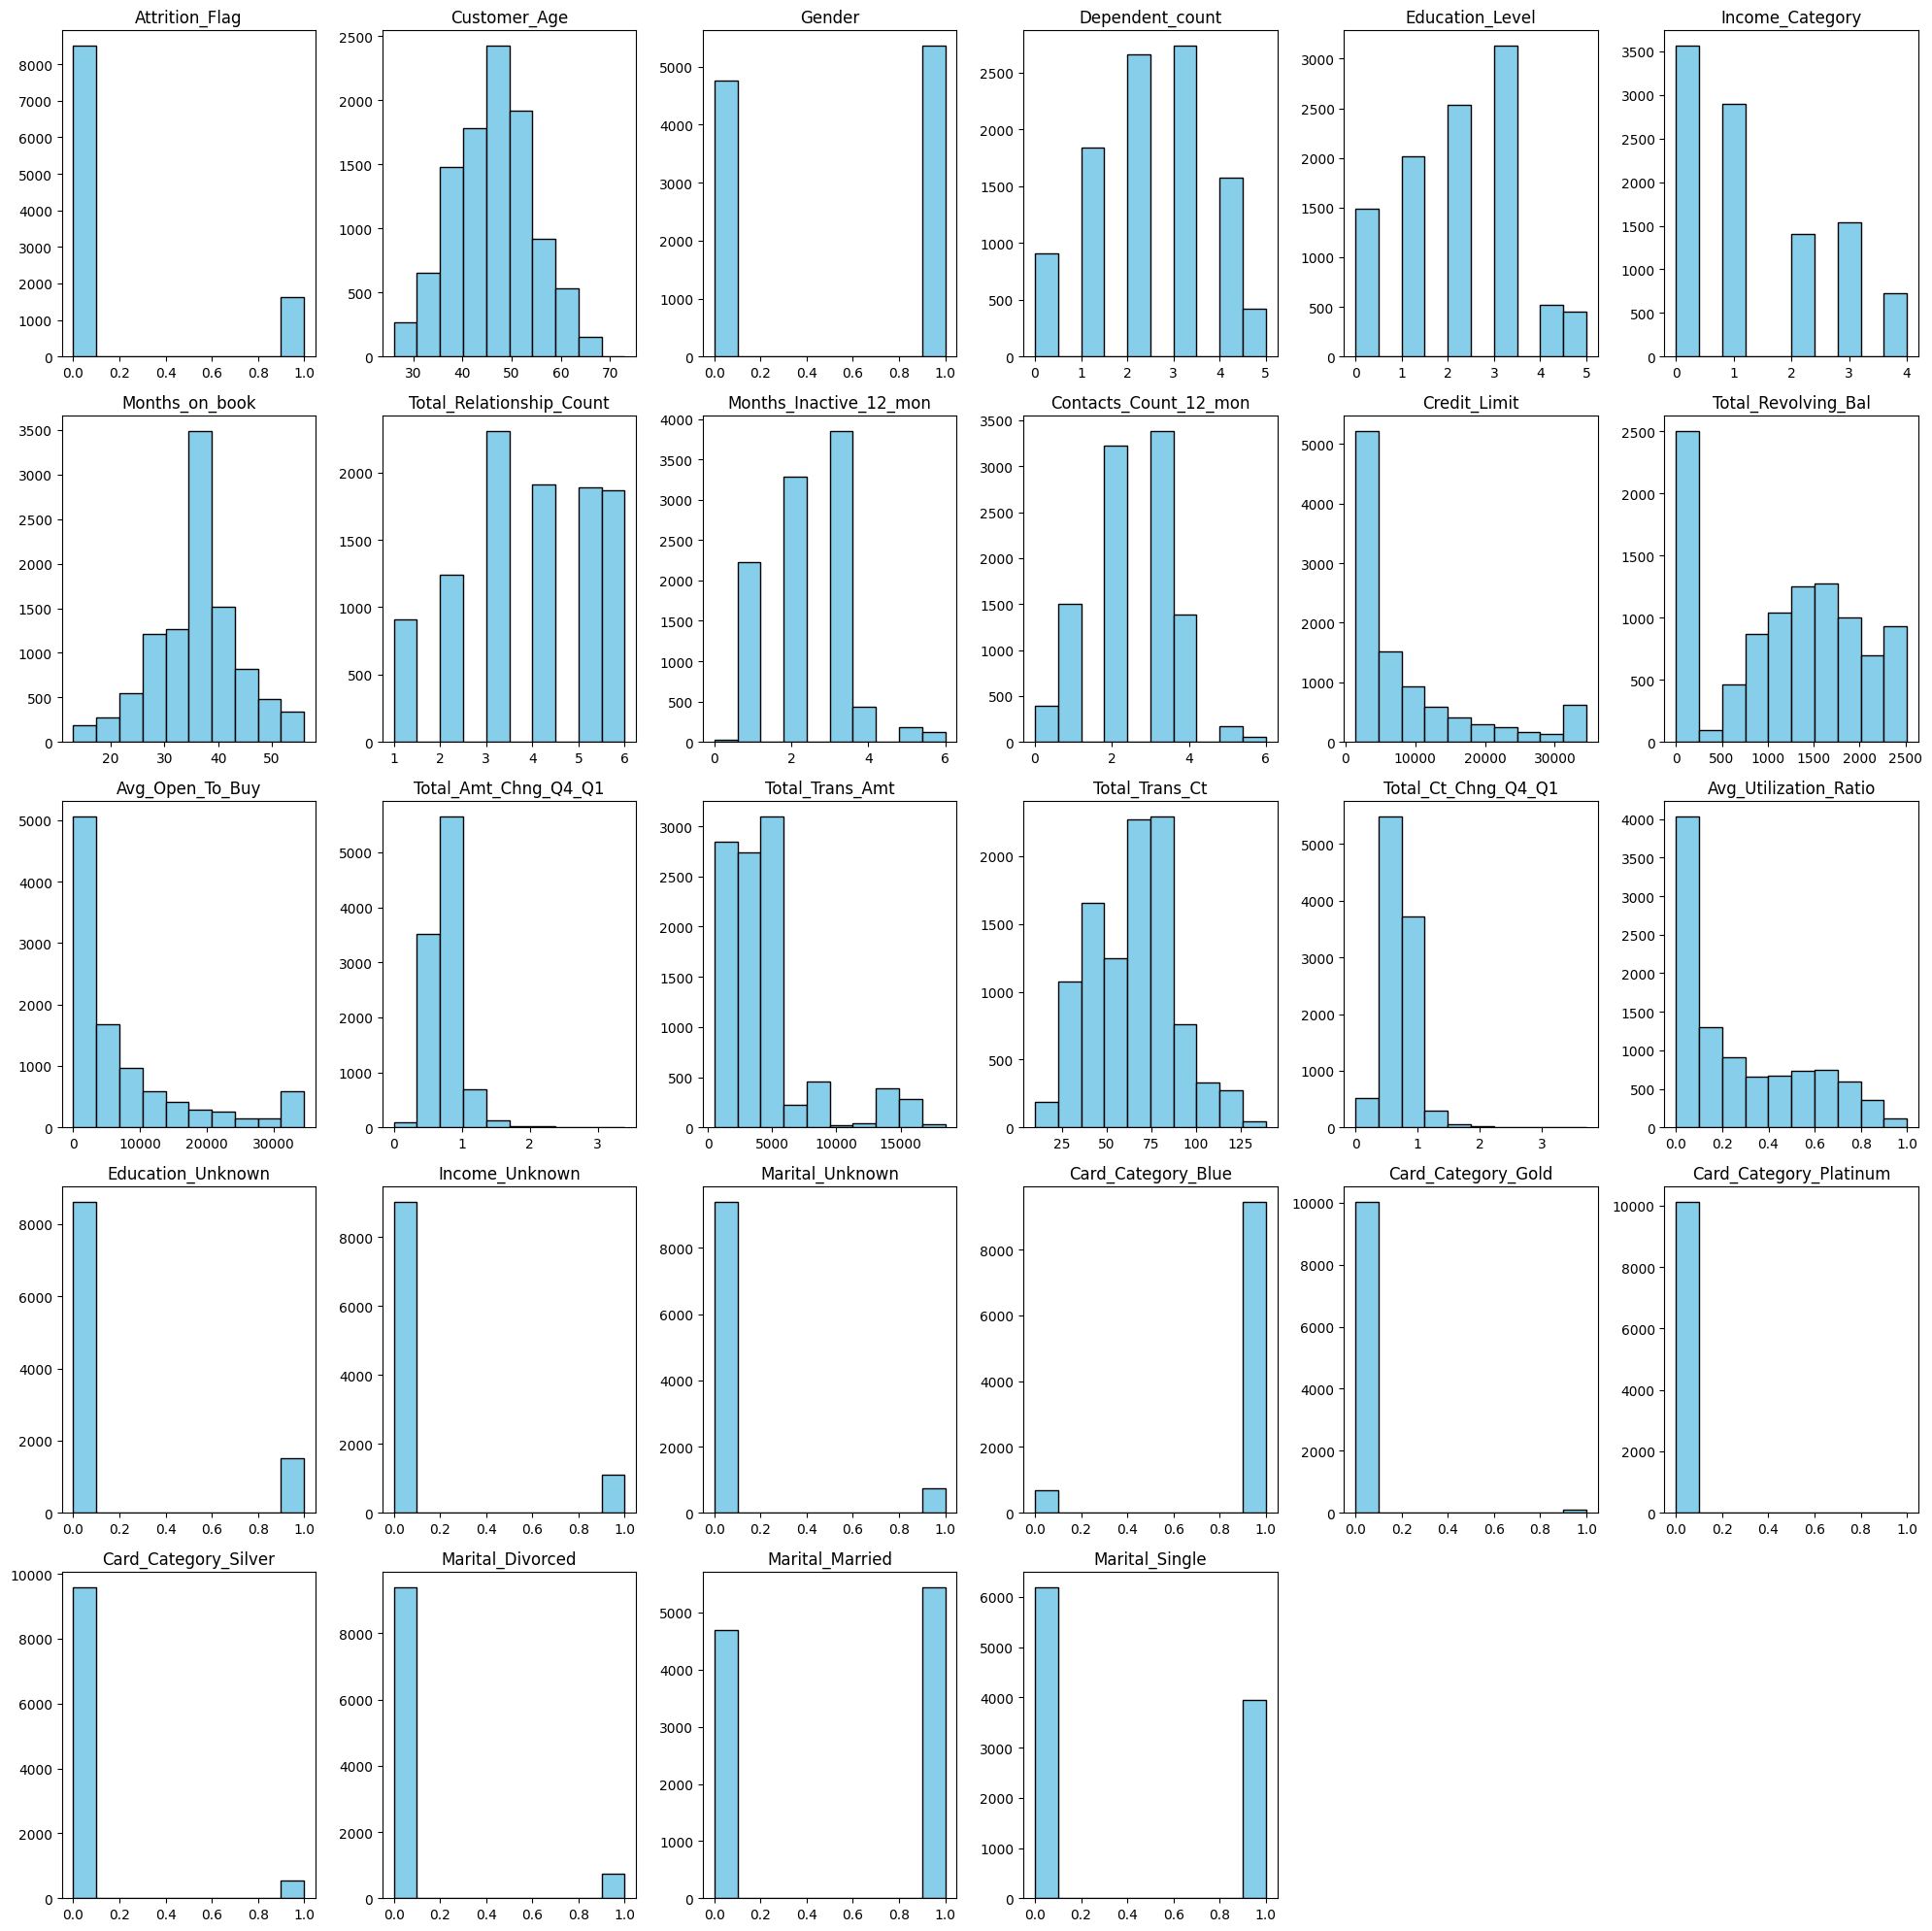

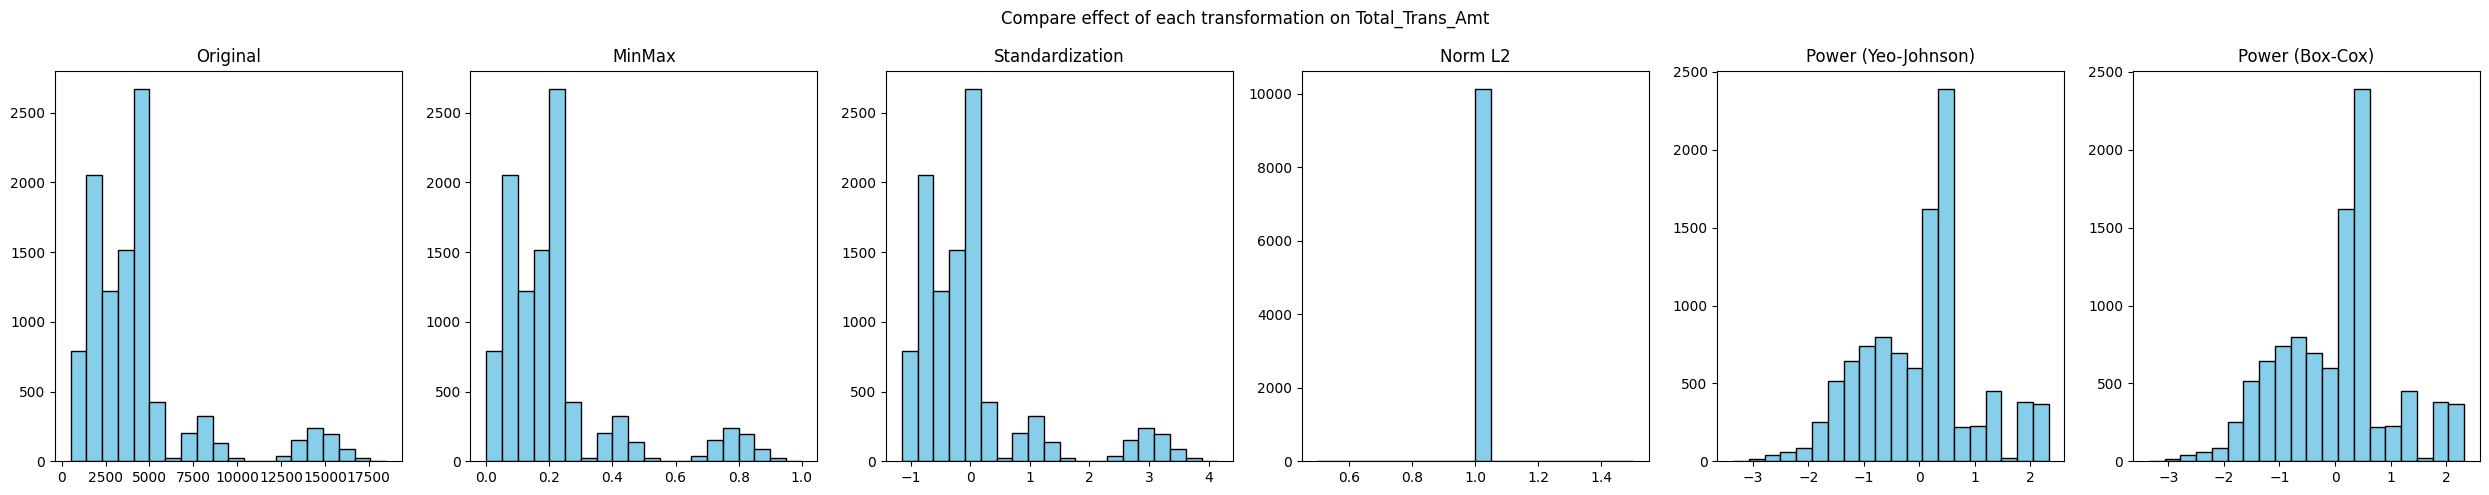

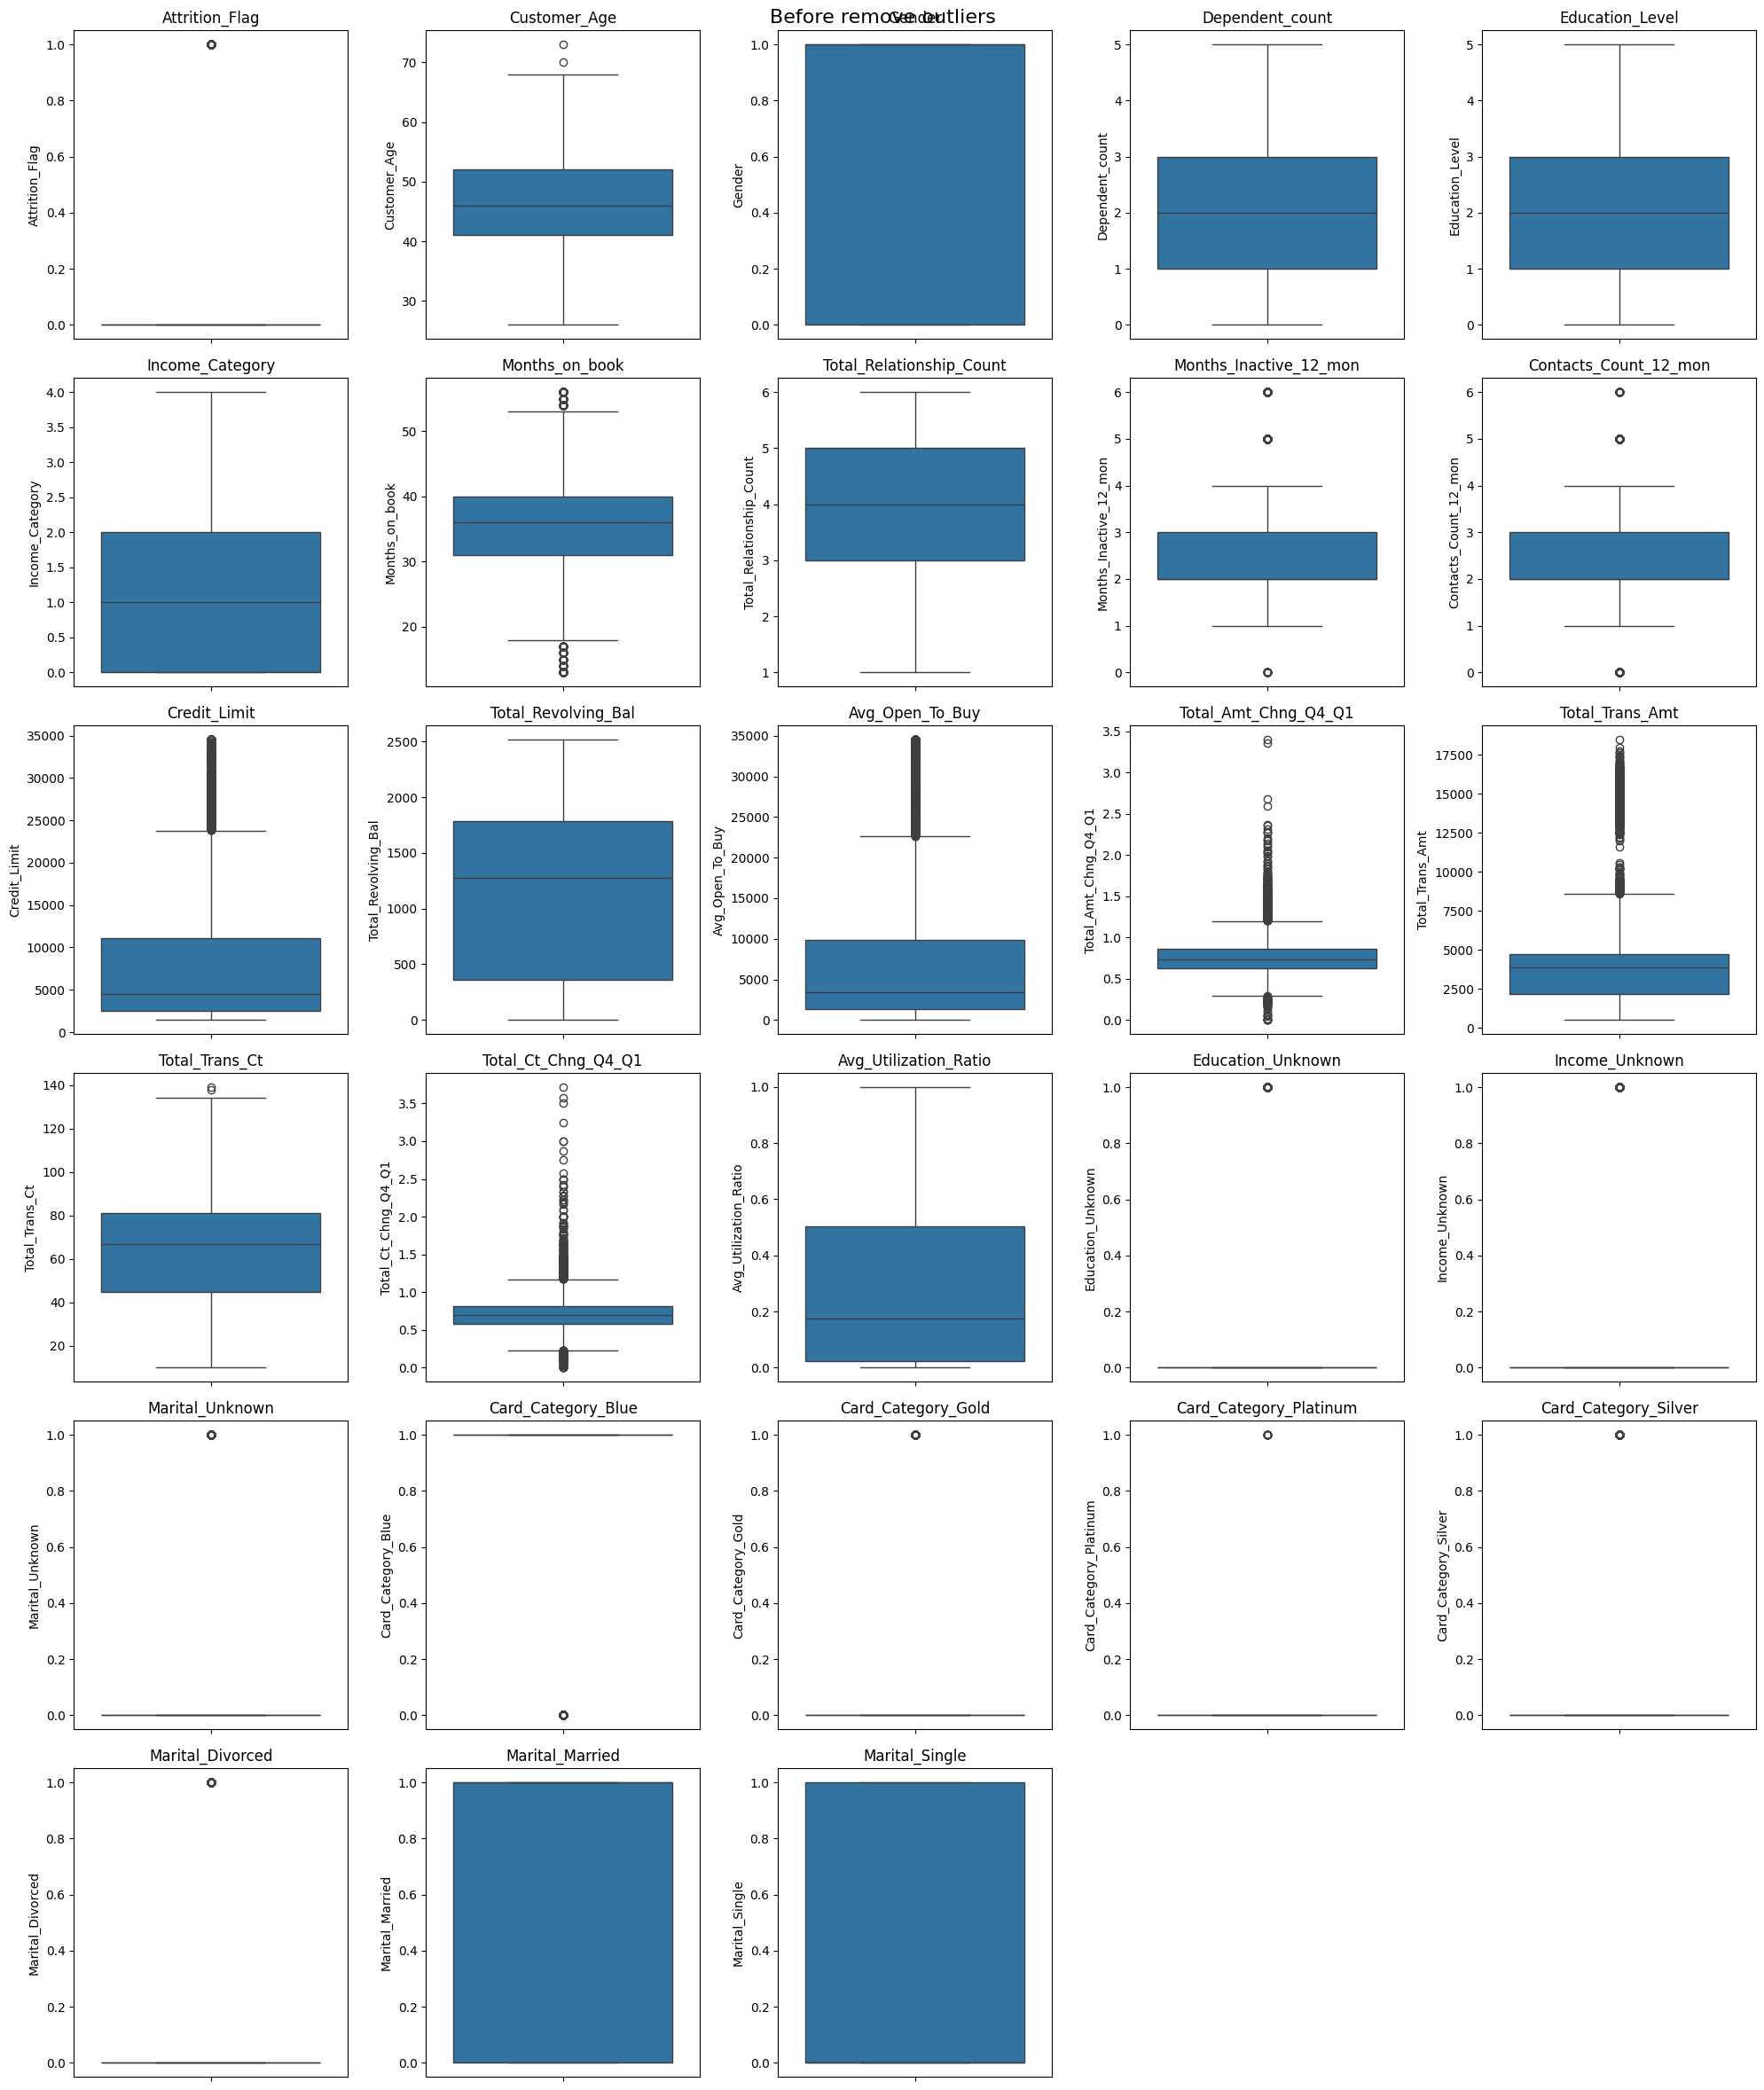

In [1]:
import import_ipynb
import data_analysis
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis.Xr_train[reg_features]
Xr_test = data_analysis.Xr_test[reg_features]
yr_train = data_analysis.yr_train
yr_test = data_analysis.yr_test

continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']
scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()
Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

# index ตาม reg_features: 0=Income_Category, 1=Card_Category_Blue, 2=Total_Trans_Amt,
# 3=Card_Category_Silver, 4=Total_Trans_Ct, 5=Card_Category_Gold, 6=Dependent_count
spline_features = [0, 2, 4, 6]
fixed_linear_features = [1, 3, 5]

In [3]:
class MARS:
    def __init__(self, max_terms=25, n_knots=20, gcv_penalty=3, max_degree=1):
        self.max_terms = max_terms
        self.n_knots = n_knots
        self.gcv_penalty = gcv_penalty
        self.max_degree = max_degree
        self.basis_functions = []
        self.fixed_linear_features = []
        self.coef_ = None

    @staticmethod
    def _hinge(x, knot, sign):
        if sign == 1:
            return np.maximum(0, x - knot)
        return np.maximum(0, knot - x)

    def _term_column(self, X, term):
        col = np.ones(X.shape[0])
        for (f_idx, knot, sign) in term:
            col = col * self._hinge(X[:, f_idx], knot, sign)
        return col

    def _build_design_matrix(self, X, basis_functions):
        n = X.shape[0]
        B = np.ones((n, 1))
        for f_idx in self.fixed_linear_features:
            B = np.hstack([B, X[:, f_idx].reshape(-1, 1)])
        for term in basis_functions:
            col = self._term_column(X, term).reshape(-1, 1)
            B = np.hstack([B, col])
        return B

    def _fit_linear(self, B, y):
        coef, *_ = np.linalg.lstsq(B, y, rcond=None)
        return coef

    def _rss(self, B, y, coef):
        return np.sum((y - B @ coef) ** 2)

    def _gcv(self, B, y, coef):
        n = len(y)
        rss = self._rss(B, y, coef)
        terms = B.shape[1]
        effective_params = terms + self.gcv_penalty * (terms - 1) / 2
        denom = (1 - effective_params / n) ** 2
        return (rss / n) / denom if denom > 0 else np.inf

    def fit(self, X, y, spline_features, fixed_linear_features):
        X = np.asarray(X)
        y = np.asarray(y).ravel()
        self.fixed_linear_features = fixed_linear_features
        self.basis_functions = []
        improved = True

        while improved and len(self.basis_functions) < self.max_terms:
            B_current = self._build_design_matrix(X, self.basis_functions)
            current_rss = self._rss(B_current, y, self._fit_linear(B_current, y))

            best_rss, best_candidate = None, None
            parents = [()] + [t for t in self.basis_functions if len(t) < self.max_degree]
            for parent in parents:
                used_features = {f for (f, k, s) in parent}
                for f_idx in spline_features:
                    if f_idx in used_features:
                        continue
                    knots = np.percentile(X[:, f_idx], np.linspace(2, 98, self.n_knots))
                    for knot in knots:
                        term_pos = parent + ((f_idx, knot, 1),)
                        term_neg = parent + ((f_idx, knot, -1),)
                        trial = self.basis_functions + [term_pos, term_neg]
                        B_trial = self._build_design_matrix(X, trial)
                        coef_trial = self._fit_linear(B_trial, y)
                        rss_trial = self._rss(B_trial, y, coef_trial)
                        if best_rss is None or rss_trial < best_rss:
                            best_rss, best_candidate = rss_trial, (term_pos, term_neg)

            if best_rss is not None and best_rss < current_rss - 1e-6:
                self.basis_functions += list(best_candidate)
            else:
                improved = False

        self._prune(X, y)
        B_final = self._build_design_matrix(X, self.basis_functions)
        self.coef_ = self._fit_linear(B_final, y)
        return self

    def _prune(self, X, y):
        current = list(self.basis_functions)
        B = self._build_design_matrix(X, current)
        best_gcv = self._gcv(B, y, self._fit_linear(B, y))
        best_functions = list(current)

        while len(current) > 0:
            gcvs = []
            for i in range(len(current)):
                trial = current[:i] + current[i + 1:]
                B_trial = self._build_design_matrix(X, trial)
                gcvs.append(self._gcv(B_trial, y, self._fit_linear(B_trial, y)))

            min_idx = int(np.argmin(gcvs))
            current = current[:min_idx] + current[min_idx + 1:]

            if gcvs[min_idx] < best_gcv:
                best_gcv = gcvs[min_idx]
                best_functions = list(current)

        self.basis_functions = best_functions

    def predict(self, X):
        X = np.asarray(X)
        B = self._build_design_matrix(X, self.basis_functions)
        return B @ self.coef_

    def describe_terms(self, feature_names=None):
        def name(i):
            return feature_names[i] if feature_names else f"x{i}"
        lines = []
        for term in self.basis_functions:
            parts = []
            for (f_idx, knot, sign) in term:
                if sign == 1:
                    parts.append(f"max(0, {name(f_idx)} - {knot:.3g})")
                else:
                    parts.append(f"max(0, {knot:.3g} - {name(f_idx)})")
            lines.append(" * ".join(parts))
        return lines

In [4]:
mars_model = MARS(max_terms=25, n_knots=20, gcv_penalty=3, max_degree=1)
mars_model.fit(Xr_train_scaled.values, yr_train, spline_features, fixed_linear_features)

y_pred_mars = mars_model.predict(Xr_test_scaled.values)

print("จำนวน basis function หลัง pruning:", len(mars_model.basis_functions))
print("R² =", r2_score(yr_test, y_pred_mars))
print("MSE =", mean_squared_error(yr_test, y_pred_mars))
print("MAE =", mean_absolute_error(yr_test, y_pred_mars))

print("\nbasis functions:")
for line in mars_model.describe_terms(feature_names=reg_features):
    print(" -", line)

จำนวน basis function หลัง pruning: 12
R² = 0.5463009215529506
MSE = 37555720.25174968
MAE = 4223.048452481829

basis functions:
 - max(0, Income_Category - 2)
 - max(0, 0.0747 - Total_Trans_Amt)
 - max(0, Total_Trans_Amt - 0.964)
 - max(0, -0.554 - Total_Trans_Amt)
 - max(0, Total_Trans_Amt - -0.985)
 - max(0, 0.0464 - Total_Trans_Ct)
 - max(0, Dependent_count - -0.26)
 - max(0, -0.287 - Total_Trans_Amt)
 - max(0, Income_Category - 3)
 - max(0, 3 - Income_Category)
 - max(0, Total_Trans_Amt - 2.55)
 - max(0, 2.55 - Total_Trans_Amt)


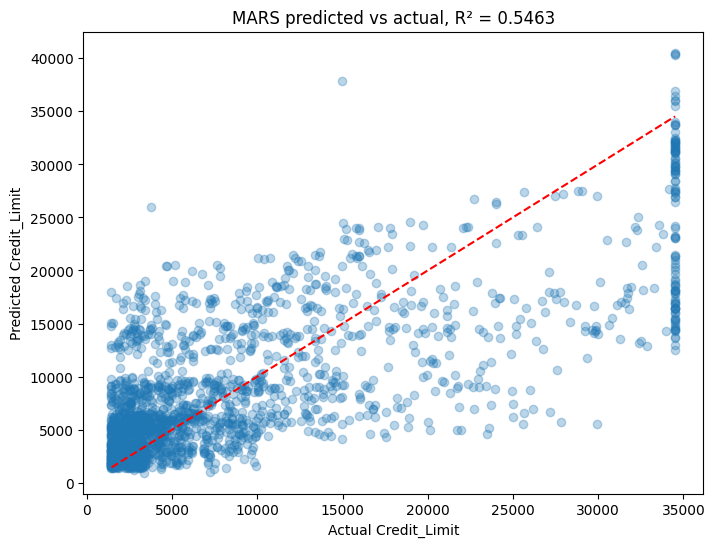

In [5]:
plt.figure(figsize=(8,6))
plt.scatter(yr_test, y_pred_mars, alpha=0.3)
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual Credit_Limit')
plt.ylabel('Predicted Credit_Limit')
plt.title(f'MARS predicted vs actual, R² = {r2_score(yr_test, y_pred_mars):.4f}')
plt.show()